In [ ]:
import sys
from pathlib import Path

# 2. Resolve project paths and add src to sys.path
PROJECT_ROOT = Path("..").resolve()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

# 3. Import pipeline modules
import cv2
import numpy as np
import matplotlib.pyplot as plt

from dataset import ImageDataset
from feature_matching import FeatureMatcher
from pose_estimation import PoseEstimator
from triangulation import Triangulator
from bundle_adjustment import BundleAdjuster
from utils import build_intrinsic_matrix, export_ply, plot_point_cloud_matplotlib, compute_rmse

# 4. Load dataset
dataset = ImageDataset()
img1 = dataset[14]
img2 = dataset[15]

height, width = img1.shape[:2]
K = build_intrinsic_matrix(width=width, height=height)

print(f"Loaded {len(dataset)} images ({width}x{height})")
print("Camera Intrinsics Matrix K:\n", K)

Loaded 177 images (1920x1280)
Camera Intrinsics Matrix K:
 [[1.5497758e+03 0.0000000e+00 9.6000000e+02]
 [0.0000000e+00 1.5463087e+03 6.4000000e+02]
 [0.0000000e+00 0.0000000e+00 1.0000000e+00]]


In [10]:
matcher = FeatureMatcher()
kp1, des1 = matcher.extract_features(img1)
kp2, des2 = matcher.extract_features(img2)
good_matches = matcher.match_and_filter_gpu(des1, des2)

print(f"Extracted {len(kp1)} keypoints from img1 and {len(kp2)} from img2.")
print(f"Filtered down to {len(good_matches)} robust matches.")

Extracted 8906 keypoints from img1 and 5071 from img2.
Filtered down to 885 robust matches.


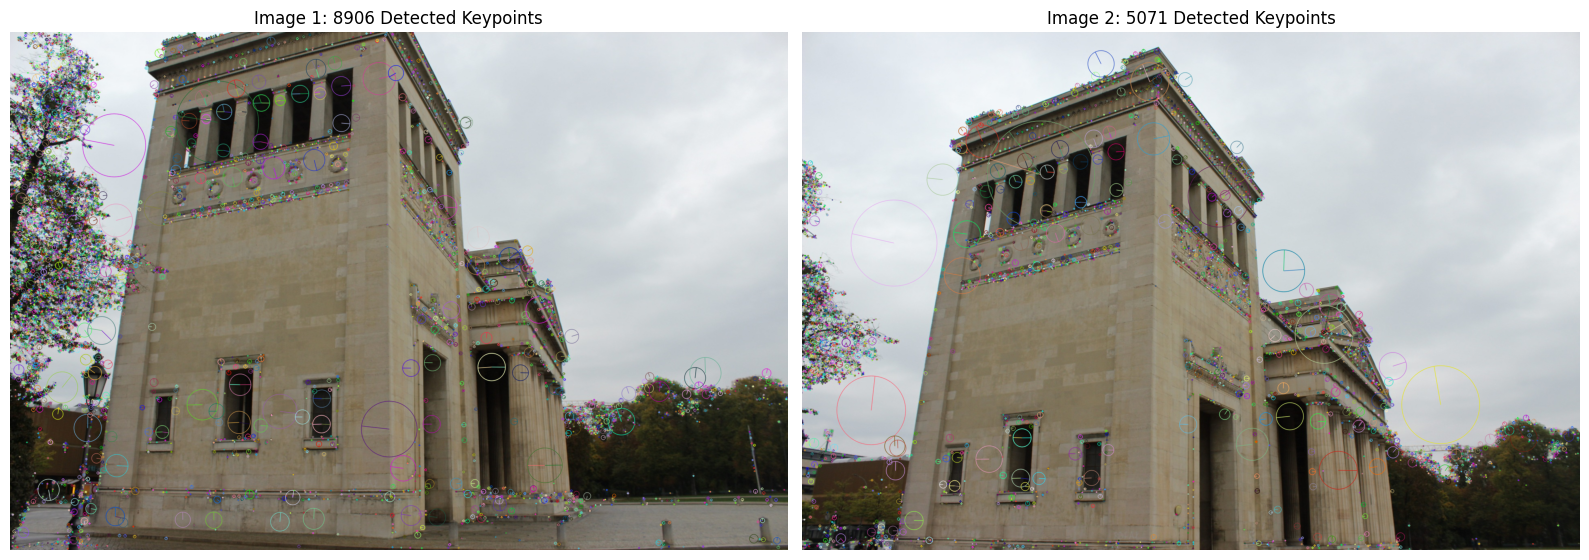

In [11]:
import cv2
import matplotlib.pyplot as plt

# 1. Draw detected keypoints onto images with orientation and scale circles
img1_kp = cv2.drawKeypoints(
    img1, kp1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
img2_kp = cv2.drawKeypoints(
    img2, kp2, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# 2. Render side-by-side (converting BGR to RGB for Matplotlib)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(cv2.cvtColor(img1_kp, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Image 1: {len(kp1)} Detected Keypoints")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(img2_kp, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Image 2: {len(kp2)} Detected Keypoints")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [12]:
estimator = PoseEstimator(K)

# 1. Extract matching (x, y) coordinates
pts1, pts2 = estimator.extract_match_coordinates(kp1, kp2, good_matches)

# 2. Compute Essential Matrix and recover R, T
E, mask = estimator.estimate_essential_matrix(pts1, pts2)
R, T = estimator.recover_camera_pose(E, pts1, pts2, mask)

print("Rotation Matrix (R):\n", R)
print("Translation Vector (T):\n", T)
print(f"Inliers remaining: {mask.sum()} / {len(mask)}")

Rotation Matrix (R):
 [[ 0.99514406  0.03334399  0.09260929]
 [-0.04000169  0.99667462  0.07098995]
 [-0.08993424 -0.07434976  0.99316864]]
Translation Vector (T):
 [[-0.94397663]
 [ 0.16156285]
 [ 0.28775955]]
Inliers remaining: 478 / 885


In [13]:
# 1. Filter raw 2D point matches using the RANSAC mask from Pose Estimation
inlier_mask = mask.ravel() == 1
pts1_inliers = pts1[inlier_mask]
pts2_inliers = pts2[inlier_mask]

# 2. Triangulate initial 3D points from 2D inliers
triangulator = Triangulator(K)
P1, P2 = triangulator.construct_projection_matrices(R, T)
pts3D_raw = triangulator.triangulate_points(P1, P2, pts1_inliers, pts2_inliers)

# 3. Filter points behind the cameras using the Cheirality Check (Z > 0)
pts3D_valid, valid_mask = triangulator.filter_cheirality(pts3D_raw, R, T)

# 4. Keep corresponding 2D inliers that produced valid 3D depth
pts1_valid = pts1_inliers[valid_mask]
pts2_valid = pts2_inliers[valid_mask]

print(f"Triangulated {len(pts3D_raw)} points.")
print(f"Valid 3D points in front of both cameras: {len(pts3D_valid)}")

Triangulated 478 points.
Valid 3D points in front of both cameras: 478


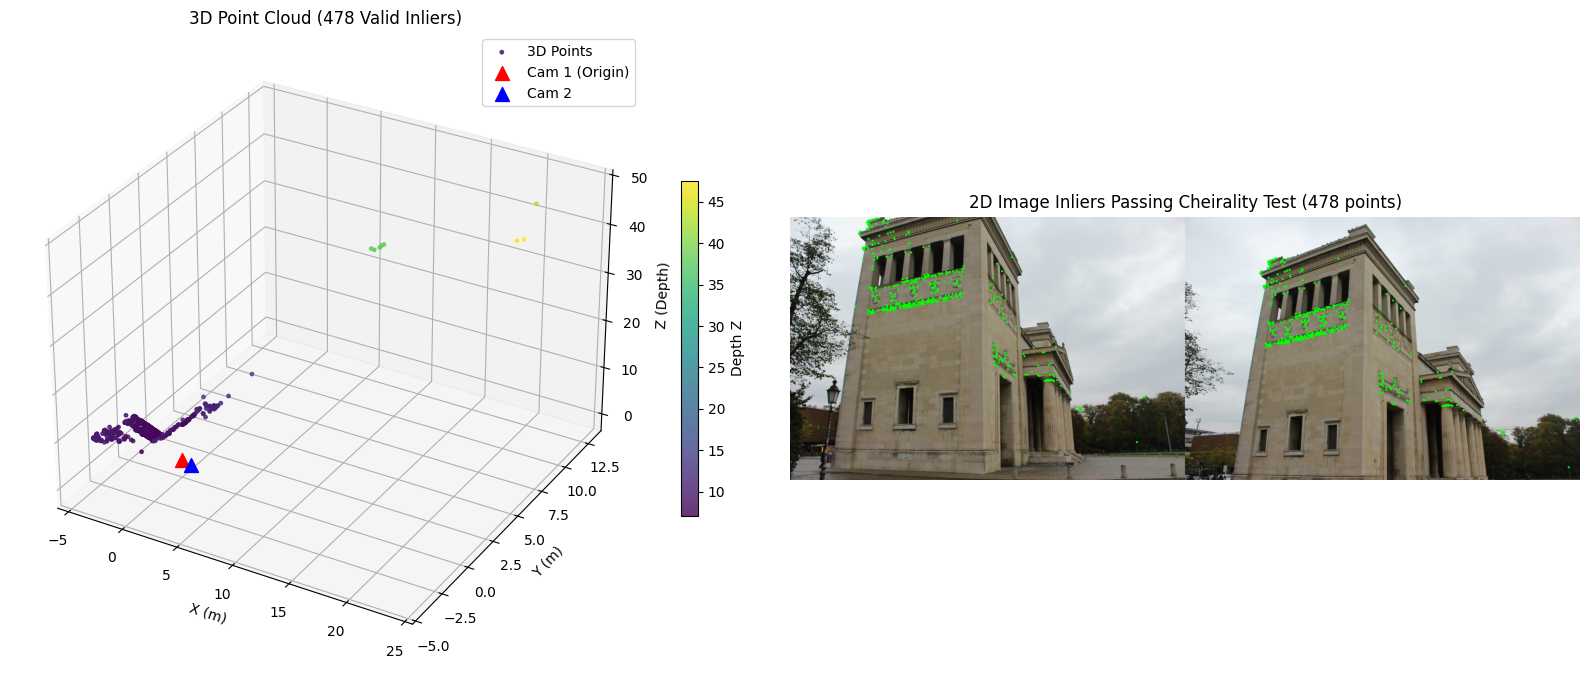

In [14]:
# Create figure for side-by-side 3D and 2D visualization
fig = plt.figure(figsize=(16, 7))


# 1. 3D Point Cloud Scatter Plot
ax_3d = fig.add_subplot(121, projection="3d")

# Plot valid triangulated 3D points (color-coded by depth Z)
scatter = ax_3d.scatter(
    pts3D_valid[:, 0],
    pts3D_valid[:, 1],
    pts3D_valid[:, 2],
    c=pts3D_valid[:, 2],
    cmap="viridis",
    s=6,
    alpha=0.8,
    label="3D Points",
)

# Compute camera centers in world space
# Camera 1 center is at origin (0, 0, 0)
cam1_center = np.array([0, 0, 0])
# Camera 2 center C2 = -R^T * T
cam2_center = (-R.T @ T).ravel()

ax_3d.scatter(*cam1_center, c="red", s=100, marker="^", label="Cam 1 (Origin)")
ax_3d.scatter(*cam2_center, c="blue", s=100, marker="^", label="Cam 2")

ax_3d.set_xlabel("X (m)")
ax_3d.set_ylabel("Y (m)")
ax_3d.set_zlabel("Z (Depth)")
ax_3d.set_title(f"3D Point Cloud ({len(pts3D_valid)} Valid Inliers)")
ax_3d.legend()
fig.colorbar(scatter, ax=ax_3d, shrink=0.5, label="Depth Z")


# 2. 2D Pixel Overlay of Triangulated Keypoints
img1_vis = img1.copy()
img2_vis = img2.copy()

# Overlay green circles on pixels that produced valid 3D points
for pt1, pt2 in zip(pts1_valid, pts2_valid):
    cv2.circle(img1_vis, (int(pt1[0]), int(pt1[1])), 5, (0, 255, 0), -1)
    cv2.circle(img2_vis, (int(pt2[0]), int(pt2[1])), 5, (0, 255, 0), -1)

# Concatenate images horizontally
side_by_side = cv2.hconcat([img1_vis, img2_vis])

ax_2d = fig.add_subplot(122)
ax_2d.imshow(cv2.cvtColor(side_by_side, cv2.COLOR_BGR2RGB))
ax_2d.set_title(
    f"2D Image Inliers Passing Cheirality Test ({len(pts1_valid)} points)"
)
ax_2d.axis("off")

plt.tight_layout()
plt.show()

In [15]:
optimizer = BundleAdjuster(K)
pts3D_init, valid_mask = triangulator.filter_cheirality(pts3D_raw, R, T)
# 1. Prepare initial flattened parameter vector for initial RMSE
rvec_init, _ = cv2.Rodrigues(R)
params_init = np.hstack(
    [rvec_init.flatten(), T.flatten(), pts3D_init.flatten()]
)

# 2. Compute initial residuals and RMSE
init_residuals = optimizer.compute_reprojection_residuals(
    params_init, len(pts3D_init), pts1_valid, pts2_valid
)
init_rmse = compute_rmse(init_residuals)

# 3. Run Bundle Adjustment optimization
pts3D_opt, R_opt, T_opt, opt_rmse = optimizer.optimize_2view(
    pts3D_init=pts3D_init,
    R_init=R,
    T_init=T,
    pts1_2d=pts1_valid,
    pts2_2d=pts2_valid,
)

print(f"Initial Reprojection RMSE: {init_rmse:.4f} px")
print(f"Optimized Reprojection RMSE: {opt_rmse:.4f} px")

Initial Reprojection RMSE: 0.1803 px
Optimized Reprojection RMSE: 0.2424 px


Exporting .ply files and plotting point clouds...
Successfully exported 478 3D points to outputs/initial_point_cloud.ply
Successfully exported 478 3D points to outputs/optimized_point_cloud.ply


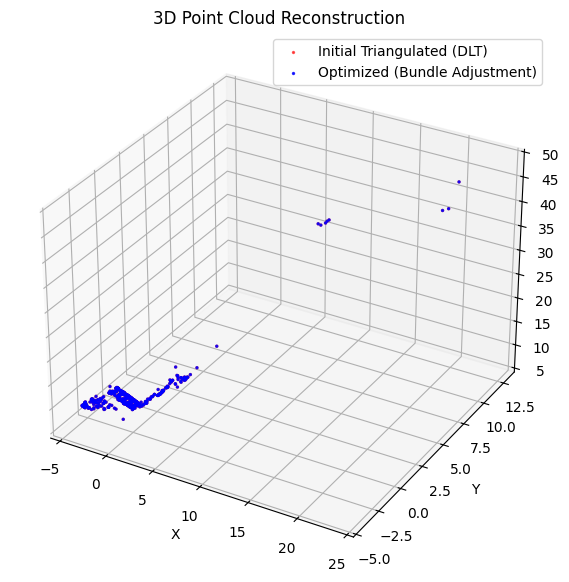

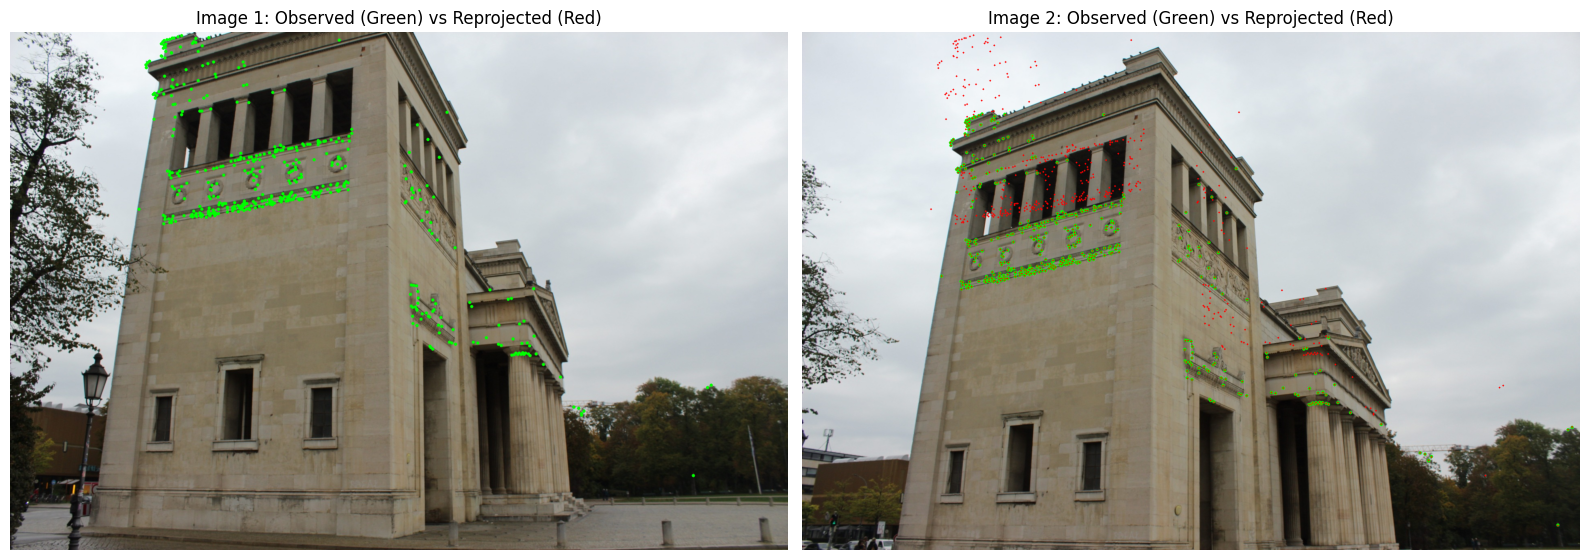

In [16]:
print("Exporting .ply files and plotting point clouds...")
export_ply("outputs/initial_point_cloud.ply", pts3D_init)
export_ply("outputs/optimized_point_cloud.ply", pts3D_opt)
plot_point_cloud_matplotlib(pts3D_init, pts3D_opt)
# 1. Project optimized 3D points back to Camera 1 (Origin)
proj1 = (K @ pts3D_opt.T).T
reproj1 = proj1[:, :2] / proj1[:, 2:]

# 2. Project optimized 3D points back to Camera 2 (R_opt, T_opt)
proj2 = (K @ (R_opt @ pts3D_opt.T + T_opt)).T
reproj2 = proj2[:, :2] / proj2[:, 2:]

# 3. Create visual copies
img1_vis = img1.copy()
img2_vis = img2.copy()

# 4. Draw observed 2D points (Green) vs. Reprojected 3D points (Red)
for pt_obs, pt_rep in zip(pts1_valid, reproj1):
  # Observed SIFT point
  cv2.circle(img1_vis, (int(pt_obs[0]), int(pt_obs[1])), 4, (0, 255, 0), -1)
  # Reprojected 3D point
  cv2.circle(img2_vis, (int(pt_rep[0]), int(pt_rep[1])), 2, (0, 0, 255), -1)

for pt_obs, pt_rep in zip(pts2_valid, reproj2):
  cv2.circle(img2_vis, (int(pt_obs[0]), int(pt_obs[1])), 4, (0, 255, 0), -1)
  cv2.circle(img2_vis, (int(pt_rep[0]), int(pt_rep[1])), 2, (0, 0, 255), -1)

# 5. Display side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(cv2.cvtColor(img1_vis, cv2.COLOR_BGR2RGB))
axes[0].set_title("Image 1: Observed (Green) vs Reprojected (Red)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(img2_vis, cv2.COLOR_BGR2RGB))
axes[1].set_title("Image 2: Observed (Green) vs Reprojected (Red)")
axes[1].axis("off")

plt.tight_layout()
plt.show()